# Used Car Price Prediction Using Regression

## 1. Project Overview

### Problem Statement
The price of a used car depends on several factors, such as its manufacturing year, kilometers driven, fuel type, transmission, ownership history, and brand. Estimating a fair resale price can be difficult because these factors influence the car's market value.

### Objective
The objective of this project is to develop supervised machine learning regression models that predict the selling price of a used car based on its features.

### Machine Learning Approach
This is a **Supervised Learning – Regression** problem because the model learns from labeled historical data, where the input features and actual selling prices are known. The target variable is continuous.

### Project Goals
- Understand and explore the used car dataset.
- Perform data cleaning and preprocessing.
- Identify the features that influence car prices.
- Train and compare different regression algorithms.
- Evaluate model performance using appropriate regression metrics.
- Select the most suitable model based on evaluation results.

### Algorithms to Be Explored
- Linear Regression
- Polynomial Regression
- Ridge Regression
- Lasso Regression
- Decision Tree Regressor
- Random Forest Regressor
- Gradient Boosting Regressor

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R-squared (\(R^2\))

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("taeefnajib/used-car-price-prediction-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/taeefnajib/used-car-price-prediction-dataset


# Import libraries and load data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
import os 

In [3]:
# Check the contents of the directory
dataset_path = '/kaggle/input/datasets/taeefnajib/used-car-price-prediction-dataset'
print(os.listdir(dataset_path))

# Once you know the exact file name (e.g., 'used_cars.csv'), load it like this:
# df = pd.read_csv(os.path.join(dataset_path, 'your_filename.csv'))

['used_cars.csv']


In [4]:
#load dataset 
file_path = os.path.join(dataset_path, 'used_cars.csv')
df = pd.read_csv(file_path)

In [5]:
#load top 5 rows  
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [6]:
#load last 5 rows
df.tail()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
4004,Bentley,Continental GT Speed,2023,714 mi.,Gasoline,6.0L W12 48V PDI DOHC Twin Turbo,8-Speed Automatic with Auto-Shift,C / C,Hotspur,None reported,Yes,"$349,950"
4005,Audi,S4 3.0T Premium Plus,2022,"10,900 mi.",Gasoline,349.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,"$53,900"
4006,Porsche,Taycan,2022,"2,116 mi.",NaN,Electric,Automatic,Black,Black,None reported,NaN,"$90,998"
4007,Ford,F-150 Raptor,2020,"33,000 mi.",Gasoline,450.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,A/T,Blue,Black,None reported,Yes,"$62,999"
4008,BMW,X3 xDrive30i,2020,"43,000 mi.",Gasoline,248.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,A/T,Gray,Brown,At least 1 accident or damage reported,Yes,"$40,000"


# Basic data inspection

In [7]:
#Dataset dimension 
print('shape: ', df.shape)
print('--'*50)
#Column names and data types
df.info()
print('--'*50)
#Statistical summary
display(df.describe(include='all').T)
print('--'*50)
#Missing values 
print(df.isnull().sum())
print('--'*50)
#Duplicate rows
print('Duplicate rows: ', df.duplicated().sum())

shape:  (4009, 12)
----------------------------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB
----------------------------------------------------------------------------------------------------


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,4009,57,Ford,386,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,4009,1898,M3 Base,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model_year,4009.0,NaN,NaN,NaN,2015.51559,6.104816,1974.0,2012.0,2017.0,2020.0,2024.0
milage,4009,2818,"110,000 mi.",16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel_type,3839,7,Gasoline,3309,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,4009,1146,2.0L I4 16V GDI DOHC Turbo,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,4009,62,A/T,1037,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ext_col,4009,319,Black,905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
int_col,4009,156,Black,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
accident,3896,2,None reported,2910,NaN,NaN,NaN,NaN,NaN,NaN,NaN


----------------------------------------------------------------------------------------------------
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64
----------------------------------------------------------------------------------------------------
Duplicate rows:  0


In [8]:
# Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical columns:", numerical_cols)
print('--'*50)
print("Categorical columns:", categorical_cols)

Numerical columns: ['model_year']
----------------------------------------------------------------------------------------------------
Categorical columns: ['brand', 'model', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']


# Data cleaning and Feature Engineering 

In [9]:
strange_values =  ['-', '--', '–', '?', 'not supported', 'none', 'null', 'N/A', 'na', ' ', '']
df = df.replace(strange_values, np.nan)
df.isnull().sum()

brand             0
model             0
model_year        0
milage            0
fuel_type       217
engine           45
transmission      4
ext_col          15
int_col         133
accident        113
clean_title     596
price             0
dtype: int64

In [10]:
print(df['fuel_type'].value_counts())
print('--'*20)
print(df['fuel_type'].unique())
print('--'*20)
print(df['engine'].value_counts())
print('--'*20)
print(df['engine'].unique())
print('--'*20)
print(df['accident'].value_counts())
print('--'*20)
print(df['accident'].unique())
print('--'*20)
print(df['clean_title'].value_counts())
print('--'*20)
print(df['clean_title'].unique())

fuel_type
Gasoline          3309
Hybrid             194
E85 Flex Fuel      139
Diesel             116
Plug-In Hybrid      34
Name: count, dtype: int64
----------------------------------------
['E85 Flex Fuel' 'Gasoline' 'Hybrid' nan 'Diesel' 'Plug-In Hybrid']
----------------------------------------
engine
2.0L I4 16V GDI DOHC Turbo                               52
355.0HP 5.3L 8 Cylinder Engine Gasoline Fuel             48
420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel             47
300.0HP 3.0L Straight 6 Cylinder Engine Gasoline Fuel    44
240.0HP 2.0L 4 Cylinder Engine Gasoline Fuel             42
                                                         ..
224.0HP 2.5L 4 Cylinder Engine Gasoline Fuel              1
221.0HP 2.5L 4 Cylinder Engine Plug-In Electric/Gas       1
540.0HP 5.4L 8 Cylinder Engine Gasoline Fuel              1
602.0HP 5.2L 10 Cylinder Engine Gasoline Fuel             1
176.0HP 2.5L 4 Cylinder Engine Gasoline Fuel              1
Name: count, Length: 1145, dtype

In [11]:
df['model'] = df['model'].astype(str).str.lower()
df['fuel_type'] = df['fuel_type'].astype(str).str.lower()

In [12]:
df['price_clean'] = df['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
df['milage_clean'] = df['milage'].astype(str).str.replace(' mi.', '', regex=False).str.replace(',', '', regex=False).astype(float)

In [13]:
df['price'] = df['price'].astype(str).str.replace(r'[\$,]', '', regex=True)
df['price'] = pd.to_numeric(df['price'], errors='coerce')

df['milage_clean'] = df['milage'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df['milage_clean'] = pd.to_numeric(df['milage_clean'], errors='coerce')

df = df.dropna(subset=['price', 'milage_clean','price_clean'])

In [14]:
df['car_age'] = 2024 - df['model_year']

In [15]:
df = df.dropna(subset=['transmission', 'ext_col', 'engine'])

In [16]:
df['fuel_type'] = df.groupby(['brand', 'model'])['fuel_type'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'Gasoline'))
df['int_col'] = df.groupby(['brand', 'model'])['int_col'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'Black'))

In [17]:
df['accident'] = df['accident'].fillna('Unknown')

In [18]:
df['clean_title'] = df['clean_title'].fillna('Unknown')

In [19]:
import re

# 1. Define your extraction functions
def extract_hp(engine):
    if pd.isna(engine): return np.nan
    match = re.search(r'(\d+(\.\d+)?)\s*HP', str(engine), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

def extract_liters(engine):
    if pd.isna(engine): return np.nan
    match = re.search(r'(\d+(\.\d+)?)\s*L', str(engine), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

In [20]:
# 2. Apply them to your dataframe 
# (Make sure 'engine' matches your actual column name, e.g., 'Engine')
df['Horsepower'] = df['engine'].apply(extract_hp)
df['Engine_Liters'] = df['engine'].apply(extract_liters)

# 3. Check a sample to see if the extraction worked properly
print(df[['engine', 'Horsepower', 'Engine_Liters']].head(10))

                                              engine  Horsepower  \
0  300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...       300.0   
1                               3.8L V6 24V GDI DOHC         NaN   
2                                     3.5 Liter DOHC         NaN   
3  354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...       354.0   
4                         2.0L I4 16V GDI DOHC Turbo         NaN   
5                                          2.4 Liter         NaN   
6       292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel       292.0   
7       282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel       282.0   
8      311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel       311.0   
9        534.0HP Electric Motor Electric Fuel System       534.0   

   Engine_Liters  
0            3.7  
1            3.8  
2            3.5  
3            3.5  
4            2.0  
5            2.4  
6            2.0  
7            4.4  
8            3.5  
9            NaN  


In [21]:
df['Horsepower'] = df.groupby(['brand', 'model'])['Horsepower'].transform(lambda x: x.fillna(x.median()))
df['Horsepower'] = df['Horsepower'].fillna(df['Horsepower'].median())

In [22]:
df['Engine_Liters'] = df.groupby(['brand', 'model'])['Engine_Liters'].transform(lambda x: x.fillna(x.median()))
df['Engine_Liters'] = df['Engine_Liters'].fillna(df['Engine_Liters'].median())

In [23]:
df.head(10)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,price_clean,milage_clean,car_age,Horsepower,Engine_Liters
0,Ford,utility police interceptor base,2013,"51,000 mi.",e85 flex fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300,10300.0,51000.0,11,300.0,3.7
1,Hyundai,palisade sel,2021,"34,742 mi.",gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005,38005.0,34742.0,3,291.0,3.8
2,Lexus,rx 350 rx 350,2022,"22,372 mi.",gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Unknown,54598,54598.0,22372.0,2,311.0,3.5
3,INFINITI,q50 hybrid sport,2015,"88,900 mi.",hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500,15500.0,88900.0,9,354.0,3.5
4,Audi,q3 45 s line premium plus,2021,"9,835 mi.",gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Unknown,34999,34999.0,9835.0,3,311.0,2.0
5,Acura,ilx 2.4l,2016,"136,397 mi.",gasoline,2.4 Liter,F,Silver,Ebony.,None reported,Unknown,14798,14798.0,136397.0,8,311.0,2.4
6,Audi,s3 2.0t premium plus,2017,"84,000 mi.",gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,None reported,Yes,31000,31000.0,84000.0,7,292.0,2.0
7,BMW,740 il,2001,"242,000 mi.",gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,None reported,Yes,7300,7300.0,242000.0,23,282.0,4.4
8,Lexus,rc 350 f sport,2021,"23,436 mi.",gasoline,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Black,Black,None reported,Yes,41927,41927.0,23436.0,3,311.0,3.5
9,Tesla,model x long range plus,2020,"34,000 mi.",nan,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,None reported,Yes,69950,69950.0,34000.0,4,534.0,3.5


# Exploratory Data Analysis

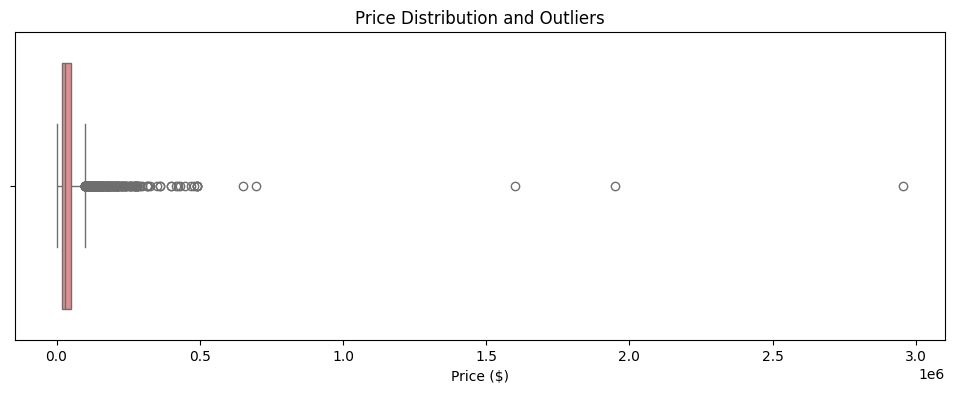

In [24]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=df['price_clean'], color='lightcoral')
plt.title('Price Distribution and Outliers')
plt.xlabel('Price ($)')
plt.show()

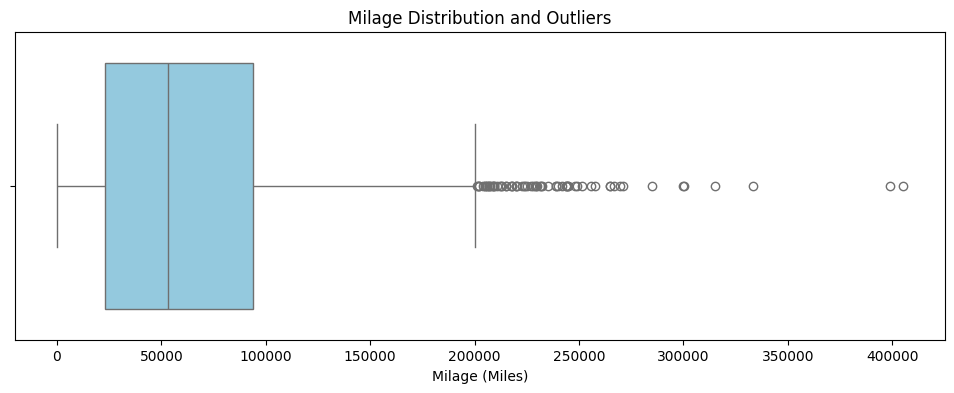

In [25]:
df = df[df['price_clean'] < 350000].copy()
plt.figure(figsize=(12, 4))
sns.boxplot(x=df['milage_clean'], color='skyblue')
plt.title('Milage Distribution and Outliers')
plt.xlabel('Milage (Miles)')
plt.show()

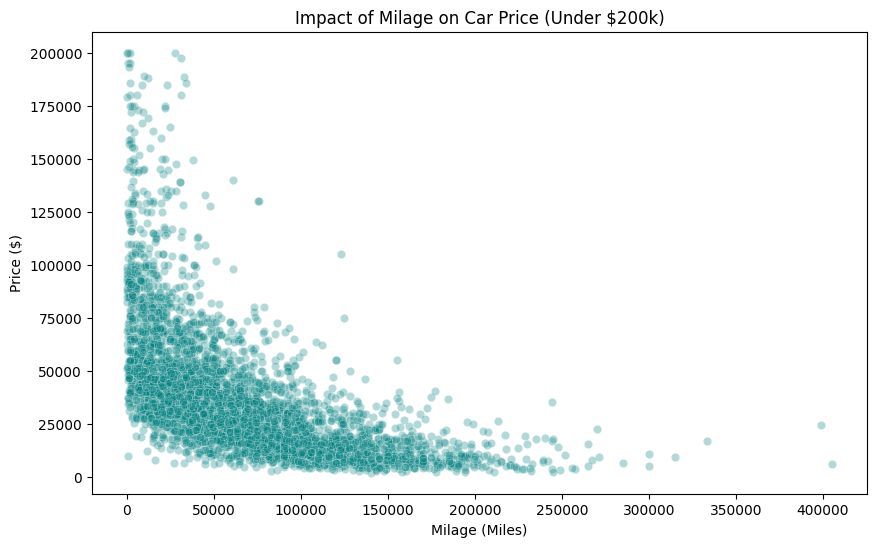

In [26]:
df_filtered = df[df['price_clean'] <= 200000]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_filtered, x='milage_clean', y='price_clean', alpha=0.3, color='teal')
plt.title('Impact of Milage on Car Price (Under $200k)')
plt.xlabel('Milage (Miles)')
plt.ylabel('Price ($)')
plt.show()

/tmp/ipykernel_23/3130256921.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=col, y='price', order=order, palette='Set2')


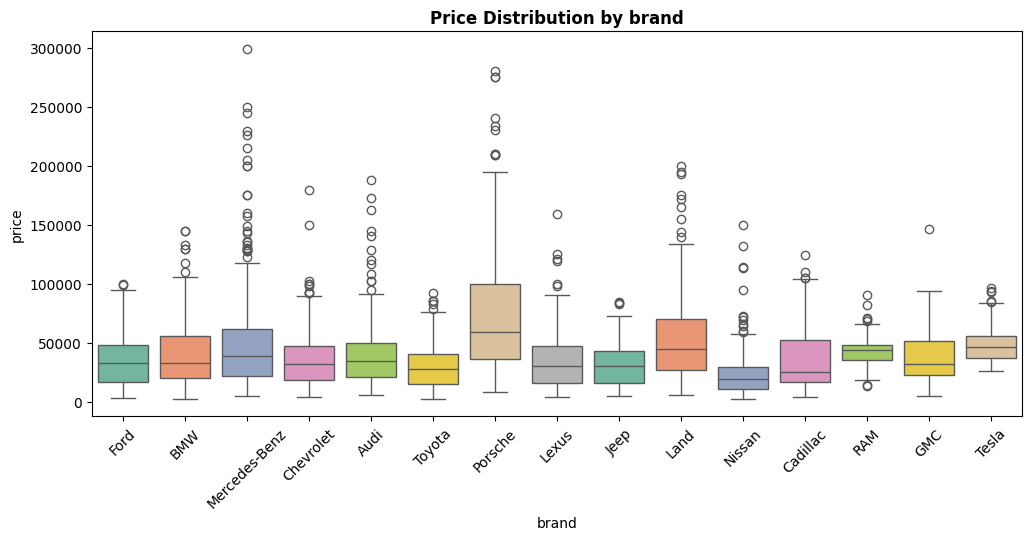

/tmp/ipykernel_23/3130256921.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=col, y='price', order=order, palette='Set2')


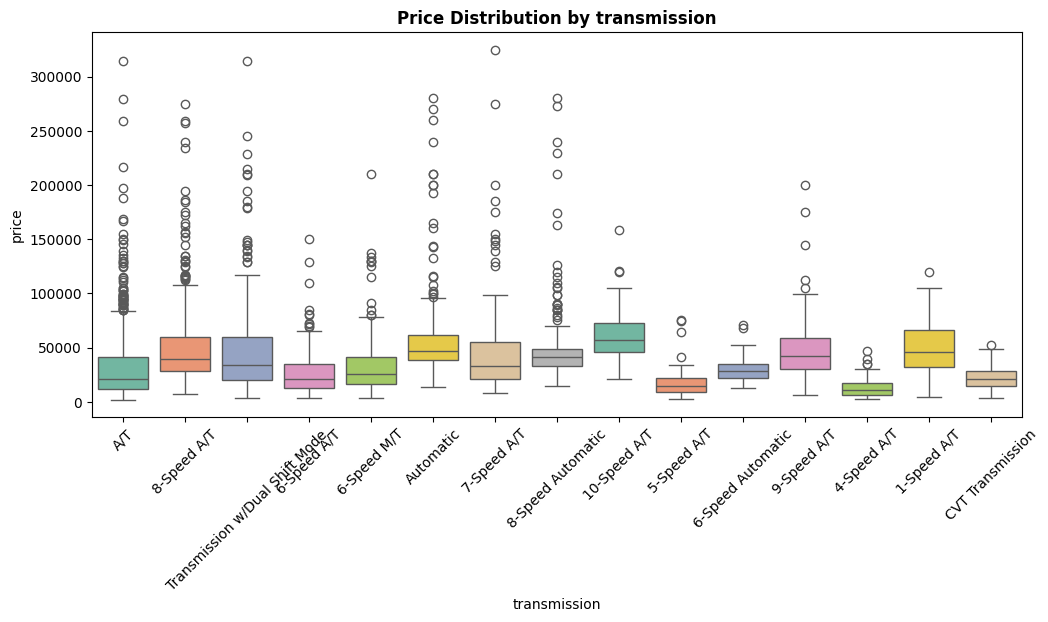

/tmp/ipykernel_23/3130256921.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=col, y='price', order=order, palette='Set2')


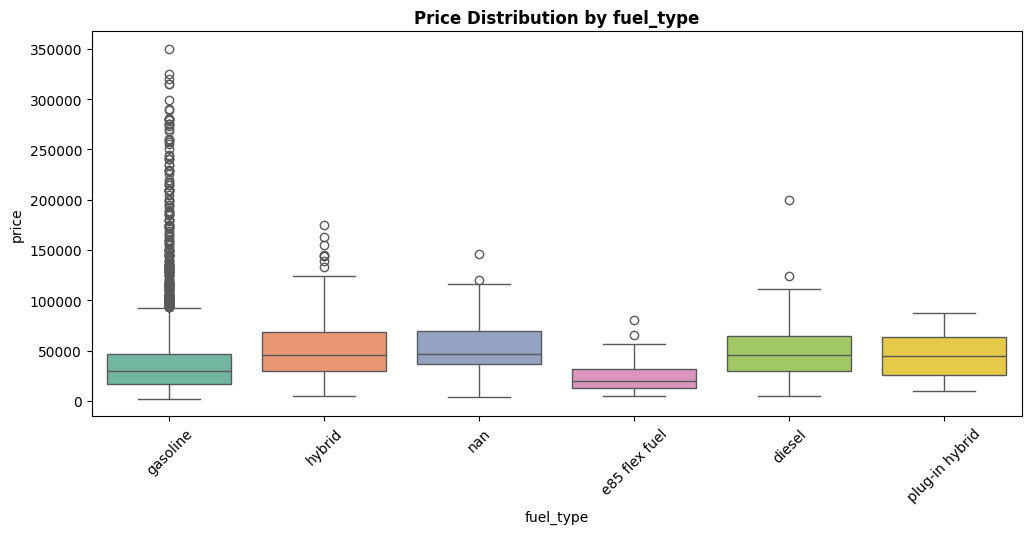

In [27]:
# Select top categorical features (e.g., brand, transmission, fuel type)
cat_features = ['brand', 'transmission', 'fuel_type'] # Modify based on your columns

for col in cat_features:
    if col in df.columns:
        plt.figure(figsize=(12, 5))
        # If there are too many unique categories (like models), limit to top 15
        order = df[col].value_counts().iloc[:15].index
        sns.boxplot(data=df, x=col, y='price', order=order, palette='Set2')
        plt.title(f'Price Distribution by {col}', fontsize=12, fontweight='bold')
        plt.xticks(rotation=45)
        plt.show()

In [28]:
# Select numerical columns that commonly have outliers
cols_to_clip = ['price', 'mileage', 'Horsepower', 'Engine_Liters']

for col in cols_to_clip:
    if col in df.columns:
        # Calculate 1st and 99th percentiles
        lower_limit = df[col].quantile(0.01)
        upper_limit = df[col].quantile(0.99)
        
        # Cap the values
        df[col] = np.clip(df[col], lower_limit, upper_limit)
        print(f"Clipped {col}: values below {lower_limit} and above {upper_limit}")

Clipped price: values below 4000.0 and above 217693.50000000003
Clipped Horsepower: values below 132.0 and above 685.3300000000004
Clipped Engine_Liters: values below 1.5 and above 6.7


In [29]:
# Function to filter outliers using IQR
def remove_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Filter data within bounds
    filtered_data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]
    return filtered_data

# Apply to price and mileage (adjust columns as needed)
initial_shape = df.shape[0]

df = remove_outliers_iqr(df, 'price')
df = remove_outliers_iqr(df, 'milage_clean')

final_shape = df.shape[0]
print(f"Removed {initial_shape - final_shape} outlier rows.")

Removed 290 outlier rows.


# Modeling 

In [30]:
#import scikit-learn libraries 
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split


In [31]:
X = df.drop('price', axis=1)
y = df['price']

In [32]:
features = ['car_age', 'milage_clean', 'Horsepower', 'Engine_Liters', 'brand', 'model', 'fuel_type', 'transmission', 'accident', 'clean_title']
X = df[features]
y_log = np.log1p(df['price_clean'])

In [33]:
categorical_cols = ['brand', 'model', 'fuel_type', 'transmission', 'accident', 'clean_title']
numerical_cols = ['car_age', 'milage_clean', 'Horsepower', 'Engine_Liters']

In [34]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)])

In [35]:
# Split into Train and Test sets
X_train, X_test, y_train_log, y_test_log = train_test_split(X, y_log, test_size=0.2, random_state=42)

In [36]:
# 1. Define the dictionary of models (excluding Polynomial Regression)
base_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = []
y_true = np.expm1(y_test_log) # Actual prices in dollar scale

# 2. Train and evaluate models safely
print("Training and evaluating models...")
for name, model in base_models.items():
    # Build pipeline combining preprocessor and current model
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    
    # Fit on training data (log scale)
    pipe.fit(X_train, y_train_log)
    
    # Get Training and Testing Accuracy (R² Score)
    train_acc = pipe.score(X_train, y_train_log) * 100
    test_acc = pipe.score(X_test, y_test_log) * 100
    
    # Predict and inverse transform back to dollars for error metrics
    y_pred_log = pipe.predict(X_test)
    y_pred = np.expm1(y_pred_log)
    
    # Calculate error metrics
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    
    results.append({
        'Model': name,
        'Training Accuracy (%)': train_acc,
        'Testing Accuracy (%)': test_acc,
        'MAE': mae,
        'RMSE': rmse,
        'R² Score': r2,
        'MSE': mse
    })

# Print detailed model breakdown including Accuracy
for res in results:
    print(f"========================================")
    print(f" Model: {res['Model']}")
    print(f"========================================")
    print(f" Training Accuracy         : {res['Training Accuracy (%)']:.2f}%")
    print(f" Testing Accuracy          : {res['Testing Accuracy (%)']:.2f}%")
    print(f" Mean Absolute Error (MAE) : ${res['MAE']:,.2f}")
    print(f" Root Mean Squared Error   : ${res['RMSE']:,.2f}")
    print("\n")

# 3. Create and display the summary DataFrame
results_df = pd.DataFrame(results)

# Reorder columns to showcase accuracy first
summary_table = results_df[['Model', 'Training Accuracy (%)', 'Testing Accuracy (%)', 'MAE', 'RMSE', 'R² Score']]

# Sort by Testing Accuracy (highest first)
summary_table = summary_table.sort_values(by='Testing Accuracy (%)', ascending=False).reset_index(drop=True)

# Format numerical columns for readability
pd.options.display.float_format = '{:,.2f}'.format
display(summary_table)

Training and evaluating models...
 Model: Linear Regression
 Training Accuracy         : 97.54%
 Testing Accuracy          : 85.43%
 Mean Absolute Error (MAE) : $5,482.55
 Root Mean Squared Error   : $8,739.16


 Model: Ridge Regression
 Training Accuracy         : 95.36%
 Testing Accuracy          : 87.92%
 Mean Absolute Error (MAE) : $5,097.71
 Root Mean Squared Error   : $7,758.65


 Model: Lasso Regression
 Training Accuracy         : 78.64%
 Testing Accuracy          : 78.77%
 Mean Absolute Error (MAE) : $7,581.99
 Root Mean Squared Error   : $11,074.04


 Model: Decision Tree
 Training Accuracy         : 100.00%
 Testing Accuracy          : 76.58%
 Mean Absolute Error (MAE) : $7,456.83
 Root Mean Squared Error   : $10,684.94


 Model: Random Forest
 Training Accuracy         : 97.95%
 Testing Accuracy          : 86.30%
 Mean Absolute Error (MAE) : $5,619.91
 Root Mean Squared Error   : $8,091.37


 Model: Gradient Boosting
 Training Accuracy         : 88.40%
 Testing Accuracy    

,Model,Training Accuracy (%),Testing Accuracy (%),MAE,RMSE,R² Score
0,Ridge Regression,95.36,87.92,"5,097.71","7,758.65",0.87
1,Random Forest,97.95,86.30,"5,619.91","8,091.37",0.86
2,Linear Regression,97.54,85.43,"5,482.55","8,739.16",0.83
3,Gradient Boosting,88.40,85.13,"6,350.15","9,060.54",0.82
4,Lasso Regression,78.64,78.77,"7,581.99","11,074.04",0.73
5,Decision Tree,100.00,76.58,"7,456.83","10,684.94",0.75


## Conclusion

In this project, I applied supervised learning regression techniques to predict used car selling prices. I explored the dataset, performed exploratory data analysis, prepared the input features, trained multiple regression algorithms, and evaluated their performance using MAE, RMSE, and \(R^2\).

The models were compared using the same test dataset to ensure a fair evaluation. The final model was selected based on its prediction errors and its ability to generalize to unseen data.

This project helped me understand the complete regression workflow, including data preprocessing, feature engineering, model training, evaluation, and model comparison.

The final model and its performance metrics will be reported based on the experimental results obtained in this notebook.